In [12]:
import pandas as pd 
df1 = pd.read_csv('data/prices_round_3_day_1.csv')
df2 = pd.read_csv('data/prices_round_3_day_2.csv')
df3 = pd.read_csv('data/prices_round_3_day_0.csv')

In [13]:
vel_df = df1[df1['product'] == 'VELVETFRUIT_EXTRACT']

<Axes: >

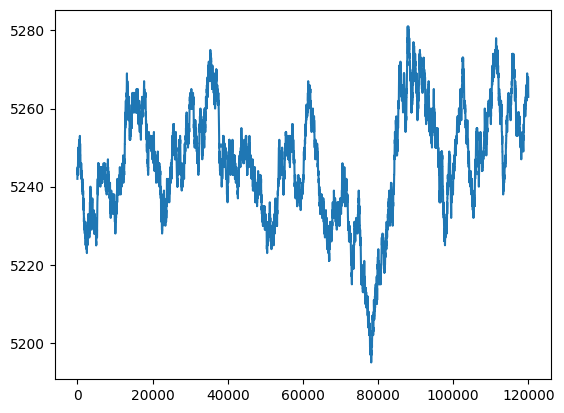

In [14]:
vel_df['bid_price_1'].plot()

In [15]:
rel_df = vel_df['bid_price_1']/vel_df['bid_price_1'].shift(1)

<Axes: >

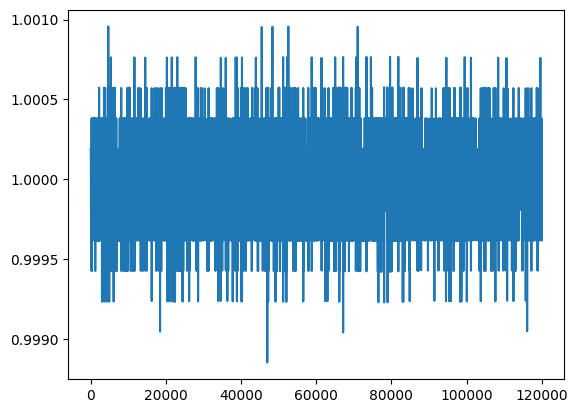

In [16]:
rel_df.plot()

Product: VELVETFRUIT_EXTRACT  |  bars: 10000
SMA(50) vs SMA(100)  |  position cap: ±200
Golden crosses: 52  |  Death crosses: 51  |  Rebalance events: 103
Total PnL (net of half-spread on turns): -108500.0000 (mid-currency / same units as P&L in CSV)


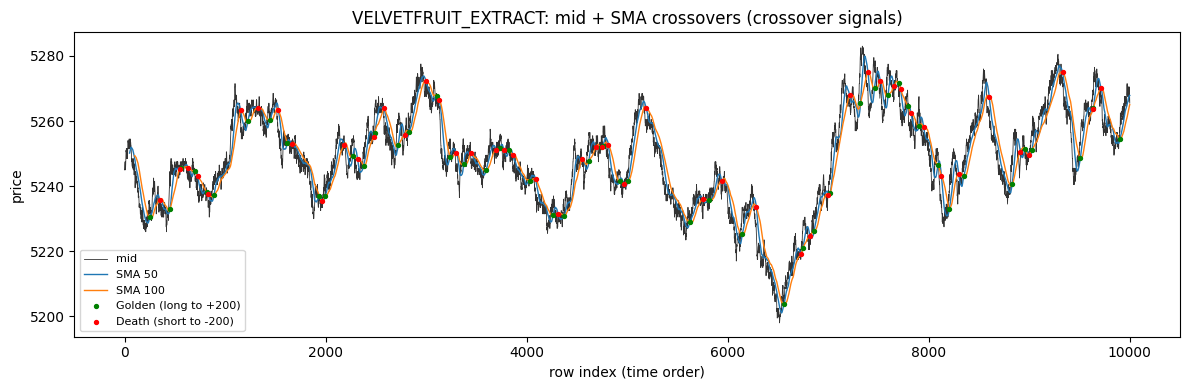

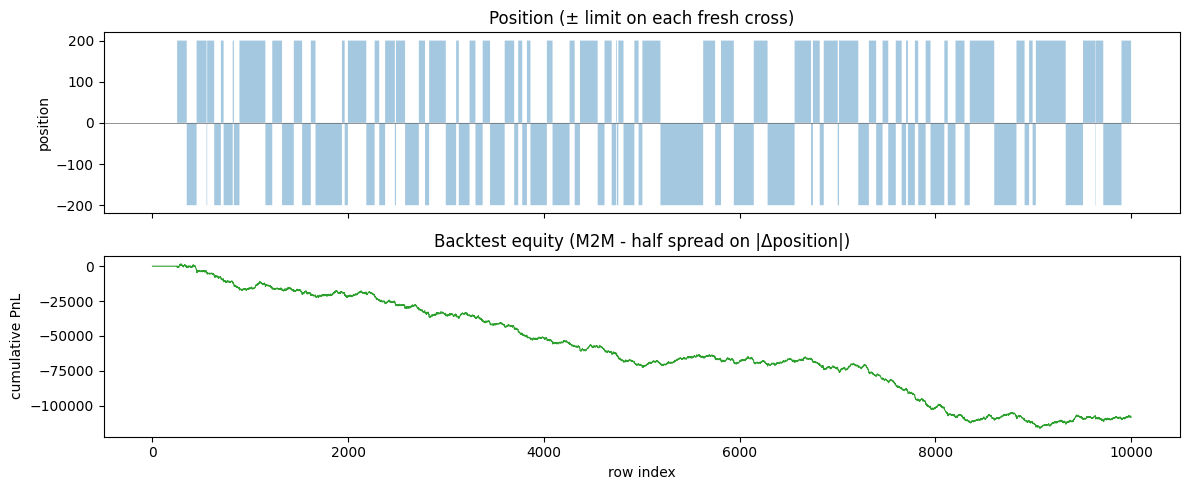

In [21]:
# --- SMA crossover strategy + backtest (position limit 200) ---
# Signal: fast SMA crosses *below* slow SMA (death cross) -> target short (-200)
#         fast SMA crosses *above* slow SMA (golden cross) -> target long (+200)
# Price: use mid (matches exchange BBO). Costs: pay half the quoted spread on position changes.

import numpy as np
import matplotlib.pyplot as plt

PRODUCT = "VELVETFRUIT_EXTRACT"
POS_LIMIT = 200
FAST_SPAN, SLOW_SPAN = 50, 100  # tune as needed

# Use one day (or concatenate days with reset_index for multi-day)
bt_df = df1[df1["product"] == PRODUCT].copy().reset_index(drop=True)
mid = bt_df["mid_price"].astype(float)
spread = (bt_df["ask_price_1"] - bt_df["bid_price_1"]).astype(float)
half_spread = (spread / 2).clip(lower=0)

sma_fast = mid.rolling(window=FAST_SPAN, min_periods=FAST_SPAN).mean()
sma_slow = mid.rolling(window=SLOW_SPAN, min_periods=SLOW_SPAN).mean()

prev_f, prev_s = sma_fast.shift(1), sma_slow.shift(1)
golden = (sma_fast > sma_slow) & (prev_f <= prev_s)   # fast crosses up through slow
death = (sma_fast < sma_slow) & (prev_f >= prev_s)   # fast crosses down through slow

n = len(bt_df)
position = np.zeros(n, dtype=np.int32)
pos = 0
for i in range(1, n):
    if bool(golden.iloc[i]):
        pos = POS_LIMIT
    elif bool(death.iloc[i]):
        pos = -POS_LIMIT
    position[i] = pos

# Per-bar PnL: mark-to-market + transaction cost on position change (|dq| * half-spread)
ret = mid.diff().fillna(0.0)
pnl_bar = position * ret.values
dpos = np.diff(position, prepend=0)
turn = np.abs(dpos)
turn_cost = turn * half_spread.values
pnl_net = pnl_bar - turn_cost
equity = np.cumsum(pnl_net)

# Summary
num_trades = int((turn > 0).sum())
print(f"Product: {PRODUCT}  |  bars: {n}")
print(f"SMA({FAST_SPAN}) vs SMA({SLOW_SPAN})  |  position cap: ±{POS_LIMIT}")
print(f"Golden crosses: {int(golden.sum())}  |  Death crosses: {int(death.sum())}  |  Rebalance events: {num_trades}")
print(f"Total PnL (net of half-spread on turns): {equity[-1]:.4f} (mid-currency / same units as P&L in CSV)")

# --- Figure 1: price + SMAs + cross markers ---
fig1, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(mid.index, mid, color="0.2", linewidth=0.6, label="mid")
ax1.plot(mid.index, sma_fast, color="C0", linewidth=1.0, label=f"SMA {FAST_SPAN}")
ax1.plot(mid.index, sma_slow, color="C1", linewidth=1.0, label=f"SMA {SLOW_SPAN}")
ax1.scatter(
    mid.index[golden.fillna(False)],
    sma_fast[golden].values,
    color="green", s=8, zorder=5, label="Golden (long to +{0})".format(POS_LIMIT),
)
ax1.scatter(
    mid.index[death.fillna(False)],
    sma_fast[death].values,
    color="red", s=8, zorder=5, label="Death (short to -{0})".format(POS_LIMIT),
)
ax1.set_title(f"{PRODUCT}: mid + SMA crossovers (crossover signals)")
ax1.set_xlabel("row index (time order)")
ax1.set_ylabel("price")
ax1.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

# --- Figure 2: position + cum PnL ---
fig2, (axa, axb) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axa.fill_between(np.arange(n), 0, position, step="post", alpha=0.4)
axa.axhline(0, color="0.4", linewidth=0.5)
axa.set_ylabel("position")
axa.set_ylim(-POS_LIMIT * 1.1, POS_LIMIT * 1.1)
axa.set_title("Position (± limit on each fresh cross)")
axb.plot(equity, color="C2", linewidth=0.8)
axb.set_ylabel("cumulative PnL")
axb.set_xlabel("row index")
axb.set_title("Backtest equity (M2M - half spread on |Δposition|)")
plt.tight_layout()
plt.show()

In [45]:
import pandas as pd
import numpy as np


def sma_orderbook_backtest(
    df,
    product,
    fast=20,
    slow=50,
    position_limit=200,
    price_col_for_signal="mid_price",
    timestamp_col=None,
    bid_price_cols=None,
    bid_volume_cols=None,
    ask_price_cols=None,
    ask_volume_cols=None,
    fee_per_unit=0.0,
    strategy_name="SMA Crossover",
    show_summary=True
):
    """
    SMA crossover backtest using bid/ask order book execution.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe containing product, mid_price, bid/ask prices and volumes.

    product : str
        Product name to backtest.

    fast : int
        Fast SMA window.

    slow : int
        Slow SMA window.

    position_limit : int
        Maximum allowed long/short position.

    price_col_for_signal : str
        Price column used for SMA calculation. Usually 'mid_price'.

    timestamp_col : str or None
        Column used for daily PnL grouping.
        If None, row-wise PnL is still calculated.

    bid_price_cols, bid_volume_cols, ask_price_cols, ask_volume_cols : list or None
        Order book column names.
        If None, default columns bid_price_1 to bid_price_3 etc. are used.

    fee_per_unit : float
        Transaction cost per unit traded.

    strategy_name : str
        Name shown in summary.

    show_summary : bool
        Whether to print summary.

    Returns
    -------
    result_df : pd.DataFrame
        Full row-wise backtest result.

    daily_df : pd.DataFrame
        Daily PnL summary.

    summary : dict
        Final performance summary.
    """

    data = df[df["product"] == product].copy()

    if data.empty:
        raise ValueError(f"No data found for product: {product}")

    data = data.sort_index().reset_index(drop=True)

    if bid_price_cols is None:
        bid_price_cols = ["bid_price_1", "bid_price_2", "bid_price_3"]

    if bid_volume_cols is None:
        bid_volume_cols = ["bid_volume_1", "bid_volume_2", "bid_volume_3"]

    if ask_price_cols is None:
        ask_price_cols = ["ask_price_1", "ask_price_2", "ask_price_3"]

    if ask_volume_cols is None:
        ask_volume_cols = ["ask_volume_1", "ask_volume_2", "ask_volume_3"]

    required_cols = (
        ["product", price_col_for_signal]
        + bid_price_cols
        + bid_volume_cols
        + ask_price_cols
        + ask_volume_cols
    )

    for col in required_cols:
        if col not in data.columns:
            raise ValueError(f"Missing required column: {col}")

    if "mid_price" not in data.columns:
        data["mid_price"] = (
            data["bid_price_1"] + data["ask_price_1"]
        ) / 2

    data["fast_sma"] = data[price_col_for_signal].rolling(
        window=fast,
        min_periods=fast
    ).mean()

    data["slow_sma"] = data[price_col_for_signal].rolling(
        window=slow,
        min_periods=slow
    ).mean()

    def execute_buy(row, quantity):
        """
        Buy quantity using ask side liquidity.
        Returns filled quantity and total cost.
        """

        remaining_qty = quantity
        filled_qty = 0
        total_cost = 0.0

        for price_col, volume_col in zip(ask_price_cols, ask_volume_cols):
            price = row[price_col]
            volume = row[volume_col]

            if pd.isna(price) or pd.isna(volume):
                continue

            available_qty = int(volume)
            trade_qty = min(remaining_qty, available_qty)

            total_cost += trade_qty * price
            filled_qty += trade_qty
            remaining_qty -= trade_qty

            if remaining_qty <= 0:
                break

        return filled_qty, total_cost

    def execute_sell(row, quantity):
        """
        Sell quantity using bid side liquidity.
        Returns filled quantity and total proceeds.
        """

        remaining_qty = quantity
        filled_qty = 0
        total_proceeds = 0.0

        for price_col, volume_col in zip(bid_price_cols, bid_volume_cols):
            price = row[price_col]
            volume = row[volume_col]

            if pd.isna(price) or pd.isna(volume):
                continue

            available_qty = int(volume)
            trade_qty = min(remaining_qty, available_qty)

            total_proceeds += trade_qty * price
            filled_qty += trade_qty
            remaining_qty -= trade_qty

            if remaining_qty <= 0:
                break

        return filled_qty, total_proceeds

    current_position = 0
    cash = 0.0
    previous_total_pnl = 0.0

    records = []

    for i, row in data.iterrows():

        mid_price = row["mid_price"]

        signal = "NO_SIGNAL"
        target_position = current_position
        trade_qty = 0
        executed_qty = 0
        avg_execution_price = np.nan
        trade_side = "HOLD"

        fast_sma_value = row["fast_sma"]
        slow_sma_value = row["slow_sma"]

        if pd.notna(fast_sma_value) and pd.notna(slow_sma_value):

            if fast_sma_value > slow_sma_value:
                signal = "LONG"
                target_position = position_limit

            elif fast_sma_value < slow_sma_value:
                signal = "SHORT"
                target_position = -position_limit

            else:
                signal = "HOLD"
                target_position = current_position

            trade_qty = target_position - current_position

            if trade_qty > 0:
                trade_side = "BUY"

                executed_qty, total_cost = execute_buy(row, trade_qty)

                if executed_qty > 0:
                    transaction_fee = executed_qty * fee_per_unit
                    cash -= total_cost
                    cash -= transaction_fee
                    current_position += executed_qty
                    avg_execution_price = total_cost / executed_qty

            elif trade_qty < 0:
                trade_side = "SELL"

                required_sell_qty = abs(trade_qty)
                executed_qty, total_proceeds = execute_sell(row, required_sell_qty)

                if executed_qty > 0:
                    transaction_fee = executed_qty * fee_per_unit
                    cash += total_proceeds
                    cash -= transaction_fee
                    current_position -= executed_qty
                    avg_execution_price = total_proceeds / executed_qty

        total_pnl = cash + current_position * mid_price
        m2m_pnl = total_pnl - previous_total_pnl
        previous_total_pnl = total_pnl

        records.append({
            "row_no": i,
            "product": product,
            "mid_price": mid_price,
            "fast_sma": fast_sma_value,
            "slow_sma": slow_sma_value,
            "signal": signal,
            "trade_side": trade_side,
            "target_position": target_position,
            "executed_qty": executed_qty,
            "avg_execution_price": avg_execution_price,
            "position": current_position,
            "cash": cash,
            "total_pnl": total_pnl,
            "m2m_pnl": m2m_pnl
        })

    result_df = pd.DataFrame(records)

    if timestamp_col is not None and timestamp_col in data.columns:
        result_df[timestamp_col] = data[timestamp_col].values
        result_df["date"] = pd.to_datetime(result_df[timestamp_col]).dt.date
    else:
        result_df["date"] = 0

    daily_df = (
        result_df
        .groupby("date")
        .agg(
            starting_position=("position", "first"),
            ending_position=("position", "last"),
            total_traded_qty=("executed_qty", "sum"),
            daily_m2m_pnl=("m2m_pnl", "sum"),
            ending_total_pnl=("total_pnl", "last"),
            ending_cash=("cash", "last"),
            ending_mid_price=("mid_price", "last")
        )
        .reset_index()
    )

    total_trades = result_df[result_df["executed_qty"] > 0].shape[0]
    gross_traded_qty = result_df["executed_qty"].sum()
    final_pnl = result_df["total_pnl"].iloc[-1]
    final_position = result_df["position"].iloc[-1]
    final_cash = result_df["cash"].iloc[-1]

    winning_periods = (result_df["m2m_pnl"] > 0).sum()
    losing_periods = (result_df["m2m_pnl"] < 0).sum()

    summary = {
        "strategy": strategy_name,
        "product": product,
        "fast_sma": fast,
        "slow_sma": slow,
        "position_limit": position_limit,
        "final_pnl": final_pnl,
        "final_position": final_position,
        "final_cash": final_cash,
        "total_trades": total_trades,
        "gross_traded_qty": gross_traded_qty,
        "winning_periods": winning_periods,
        "losing_periods": losing_periods,
        "max_drawdown": (
            result_df["total_pnl"]
            - result_df["total_pnl"].cummax()
        ).min()
    }

    if show_summary:
        print("=" * 60)
        print(f"Strategy        : {strategy_name}")
        print(f"Product         : {product}")
        print(f"Fast SMA        : {fast}")
        print(f"Slow SMA        : {slow}")
        print(f"Position Limit  : {position_limit}")
        print("-" * 60)
        print(f"Final PnL       : {final_pnl:.2f}")
        print(f"Final Position  : {final_position}")
        print(f"Final Cash      : {final_cash:.2f}")
        print(f"Total Trades    : {total_trades}")
        print(f"Gross Quantity  : {gross_traded_qty}")
        print(f"Max Drawdown    : {summary['max_drawdown']:.2f}")
        print("=" * 60)

    return result_df, daily_df, summary

In [51]:
res_df,d_df,sum_df = sma_orderbook_backtest(
    vel_df,
    'VELVETFRUIT_EXTRACT',
    fast=50,
    slow=200,
)
sum_df

Strategy        : SMA Crossover
Product         : VELVETFRUIT_EXTRACT
Fast SMA        : 50
Slow SMA        : 200
Position Limit  : 200
------------------------------------------------------------
Final PnL       : -68411.00
Final Position  : 200
Final Cash      : -1121511.00
Total Trades    : 396
Gross Quantity  : 22200
Max Drawdown    : -69411.00


{'strategy': 'SMA Crossover',
 'product': 'VELVETFRUIT_EXTRACT',
 'fast_sma': 50,
 'slow_sma': 200,
 'position_limit': 200,
 'final_pnl': np.float64(-68411.0),
 'final_position': np.int64(200),
 'final_cash': np.float64(-1121511.0),
 'total_trades': 396,
 'gross_traded_qty': np.int64(22200),
 'winning_periods': np.int64(3614),
 'losing_periods': np.int64(3899),
 'max_drawdown': -69411.0}

<Axes: >

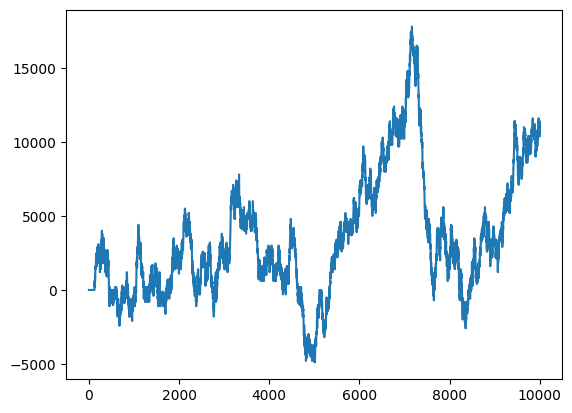

In [40]:
position_lst = simple_backtest_sma_stat(vel_df,'VELVETFRUIT_EXTRACT',50,125)
pos_df = pd.DataFrame(position_lst)
pos_df
pos_df['PnL'].plot()

np.float64(5248.3919)

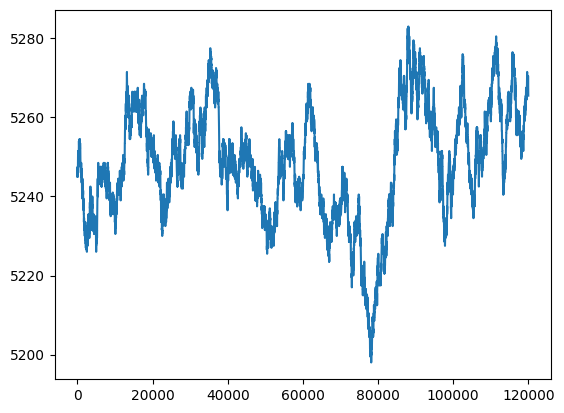

In [53]:
vel_df['mid_price'].plot()
vel_df['mid_price'].mean()

In [27]:
final_pnl = pos_df['cash'].iloc[-1]+vel_df['mid_price'].iloc[-1]*pos_df['VELVETFRUIT_EXTRACT'].iloc[-1]
print(final_pnl)

1056600.0


Strategy        : Hydrogel Static Wall-Mid MM
Product         : HYDROGEL_PACK
Rows / Days     : 30000 / 3
Final PnL       : -1104.00
Final Position  : 17
Total Trades    : 41
Gross Quantity  : 301
Max Drawdown    : -10894.00
Avg |Position|  : 40.35


,day,start_pnl,end_pnl,daily_pnl,max_drawdown,avg_abs_position,max_abs_position,trades,gross_qty,avg_trade_price
0,0,0.0,-1594.0,-1594.0,-5134.0,29.7850,57,9,75,10002.111111
1,1,-1594.0,227.0,1821.0,-7152.0,47.5327,63,23,167,9975.782609
2,2,27.0,-1104.0,-1331.0,-10894.0,43.7313,63,9,59,9969.000000


,kind,side,trades,gross_qty,avg_price
0,make,BUY,9,71,10011.888889
1,make,SELL,1,4,9930.000000
2,take,BUY,12,88,9968.750000
3,take_reduce,SELL,19,138,9974.789474


array([<Axes: >, <Axes: >], dtype=object)

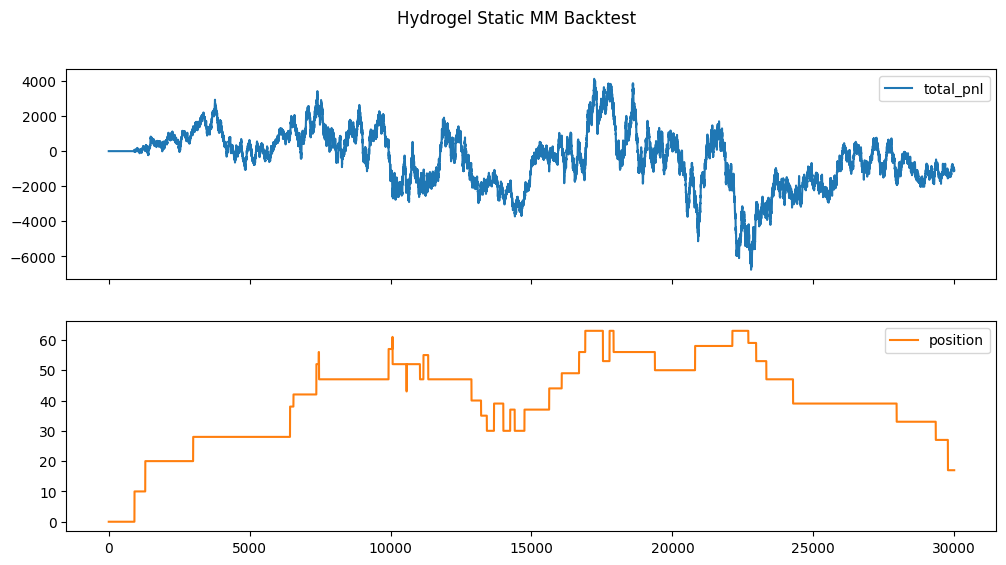

In [55]:
import pandas as pd
import numpy as np


def _book_side(row, side):
    if side == "buy":
        cols = [("bid_price_1", "bid_volume_1"), ("bid_price_2", "bid_volume_2"), ("bid_price_3", "bid_volume_3")]
        reverse = True
    else:
        cols = [("ask_price_1", "ask_volume_1"), ("ask_price_2", "ask_volume_2"), ("ask_price_3", "ask_volume_3")]
        reverse = False

    levels = []
    for price_col, volume_col in cols:
        price, volume = row.get(price_col), row.get(volume_col)
        if pd.notna(price) and pd.notna(volume) and volume != 0:
            levels.append((int(price), abs(int(volume))))
    return sorted(levels, reverse=reverse)


def _static_orders(row, position, position_limit=200, extreme_dist=0, anchor=10000):
    bids = _book_side(row, "buy")
    asks = _book_side(row, "sell")
    if not bids or not asks:
        return []

    bid_wall = min(price for price, _ in bids)
    ask_wall = max(price for price, _ in asks)
    wall_mid = (bid_wall + ask_wall) / 2
    buy_room = position_limit - position
    sell_room = position_limit + position
    orders = []

    for ask, volume in asks:
        if ask <= wall_mid - 1 and buy_room > 0:
            qty = min(volume, buy_room)
            orders.append({"side": "BUY", "price": ask, "qty": qty, "kind": "take"})
            buy_room -= qty
        elif ask <= wall_mid and position < 0 and buy_room > 0:
            qty = min(volume, abs(position), buy_room)
            orders.append({"side": "BUY", "price": ask, "qty": qty, "kind": "take_reduce"})
            buy_room -= qty

    for bid, volume in bids:
        if bid >= wall_mid + 1 and sell_room > 0:
            qty = min(volume, sell_room)
            orders.append({"side": "SELL", "price": bid, "qty": qty, "kind": "take"})
            sell_room -= qty
        elif bid >= wall_mid and position > 0 and sell_room > 0:
            qty = min(volume, position, sell_room)
            orders.append({"side": "SELL", "price": bid, "qty": qty, "kind": "take_reduce"})
            sell_room -= qty

    bid_price = int(bid_wall + 1)
    ask_price = int(ask_wall - 1)

    for bid, volume in bids:
        overbid = bid + 1
        if volume > 1 and overbid < wall_mid:
            bid_price = max(bid_price, overbid)
            break
        if bid < wall_mid:
            bid_price = max(bid_price, bid)
            break

    for ask, volume in asks:
        underbid = ask - 1
        if volume > 1 and underbid > wall_mid:
            ask_price = min(ask_price, underbid)
            break
        if ask > wall_mid:
            ask_price = min(ask_price, ask)
            break

    if extreme_dist > 0 and abs(wall_mid - anchor) > extreme_dist:
        if position > 0 and ask_price - 1 > bid_price:
            ask_price -= 1
        elif position < 0 and bid_price + 1 < ask_price:
            bid_price += 1

    if bid_price < ask_price:
        if buy_room > 0:
            orders.append({"side": "BUY", "price": bid_price, "qty": buy_room, "kind": "make"})
        if sell_room > 0:
            orders.append({"side": "SELL", "price": ask_price, "qty": sell_room, "kind": "make"})

    return orders


def _execute_order(order, row):
    fills = []
    remaining = order["qty"]
    side = order["side"]
    book = _book_side(row, "sell" if side == "BUY" else "buy")

    for price, volume in book:
        if remaining <= 0:
            break
        crosses = price <= order["price"] if side == "BUY" else price >= order["price"]
        if not crosses:
            break
        qty = min(volume, remaining)
        fills.append({"side": side, "price": price, "qty": qty, "kind": order["kind"]})
        remaining -= qty
    return fills


def bactest_stat(df, product="HYDROGEL_PACK", position_limit=200, extreme_dist=0, anchor=10000, show=True):
    data = df[df["product"] == product].copy().sort_values(["day", "timestamp"]).reset_index(drop=True)
    if data.empty:
        raise ValueError(f"No data found for {product}")

    position = 0
    cash = 0.0
    pending_orders = []
    trades = []
    equity = []

    for _, row in data.iterrows():
        fills = []
        for order in pending_orders:
            fills.extend(_execute_order(order, row))
        pending_orders = []

        for fill in fills:
            signed_qty = fill["qty"] if fill["side"] == "BUY" else -fill["qty"]
            position += signed_qty
            cash -= signed_qty * fill["price"]
            trades.append({**fill, "day": row["day"], "timestamp": row["timestamp"], "position": position, "cash": cash})

        orders = _static_orders(row, position, position_limit, extreme_dist, anchor)
        resting = []
        for order in orders:
            order_fills = _execute_order(order, row) if order["kind"].startswith("take") else []
            if order_fills:
                for fill in order_fills:
                    signed_qty = fill["qty"] if fill["side"] == "BUY" else -fill["qty"]
                    position += signed_qty
                    cash -= signed_qty * fill["price"]
                    trades.append({**fill, "day": row["day"], "timestamp": row["timestamp"], "position": position, "cash": cash})
            elif order["kind"] == "make":
                resting.append(order)
        pending_orders = resting

        total_pnl = cash + position * row["mid_price"]
        equity.append({
            "day": row["day"],
            "timestamp": row["timestamp"],
            "mid_price": row["mid_price"],
            "position": position,
            "cash": cash,
            "total_pnl": total_pnl,
        })

    equity_df = pd.DataFrame(equity)
    trades_df = pd.DataFrame(trades)
    equity_df["m2m_pnl"] = equity_df["total_pnl"].diff().fillna(equity_df["total_pnl"])
    equity_df["drawdown"] = equity_df["total_pnl"] - equity_df["total_pnl"].cummax()

    if trades_df.empty:
        trades_df = pd.DataFrame(columns=["side", "price", "qty", "kind", "day", "timestamp", "position", "cash"])

    daily_df = equity_df.groupby("day").agg(
        start_pnl=("total_pnl", "first"),
        end_pnl=("total_pnl", "last"),
        daily_pnl=("m2m_pnl", "sum"),
        max_drawdown=("drawdown", "min"),
        avg_abs_position=("position", lambda x: x.abs().mean()),
        max_abs_position=("position", lambda x: x.abs().max()),
    ).reset_index()

    daily_trades = trades_df.groupby("day").agg(
        trades=("qty", "count"),
        gross_qty=("qty", "sum"),
        avg_trade_price=("price", "mean"),
    ).reset_index()
    daily_df = daily_df.merge(daily_trades, on="day", how="left").fillna({"trades": 0, "gross_qty": 0})

    trade_by_kind = trades_df.groupby(["kind", "side"]).agg(
        trades=("qty", "count"),
        gross_qty=("qty", "sum"),
        avg_price=("price", "mean"),
    ).reset_index()

    summary = {
        "product": product,
        "rows": len(data),
        "final_pnl": equity_df["total_pnl"].iloc[-1],
        "final_position": int(equity_df["position"].iloc[-1]),
        "total_trades": int(len(trades_df)),
        "gross_qty": int(trades_df["qty"].sum()) if not trades_df.empty else 0,
        "max_drawdown": equity_df["drawdown"].min(),
        "winning_periods": int((equity_df["m2m_pnl"] > 0).sum()),
        "losing_periods": int((equity_df["m2m_pnl"] < 0).sum()),
        "avg_abs_position": equity_df["position"].abs().mean(),
    }

    if show:
        print("=" * 70)
        print("Strategy        : Hydrogel Static Wall-Mid MM")
        print(f"Product         : {product}")
        print(f"Rows / Days     : {summary['rows']} / {daily_df['day'].nunique()}")
        print(f"Final PnL       : {summary['final_pnl']:.2f}")
        print(f"Final Position  : {summary['final_position']}")
        print(f"Total Trades    : {summary['total_trades']}")
        print(f"Gross Quantity  : {summary['gross_qty']}")
        print(f"Max Drawdown    : {summary['max_drawdown']:.2f}")
        print(f"Avg |Position|  : {summary['avg_abs_position']:.2f}")
        print("=" * 70)
        display(daily_df)
        display(trade_by_kind)

    return equity_df, trades_df, daily_df, trade_by_kind, summary


all_days_df = pd.concat([df3, df1, df2], ignore_index=True)
equity_df, trades_df, daily_df, trade_by_kind, summary = bactest_stat(
    all_days_df,
    product="HYDROGEL_PACK",
    position_limit=200,
    extreme_dist=0,
    anchor=10000,
)

equity_df[["total_pnl", "position"]].plot(subplots=True, figsize=(12, 6), title="Hydrogel Static MM Backtest")


In [54]:
# Backtester is implemented in the cell above.


SyntaxError: incomplete input (1812480475.py, line 7)

In [57]:
def statergy(running_wall_mid,fast_ask_ma,slow_ask_ma,fast_bid_ma,slow_bid_ma):
    if fast_ask_ma<slow_ask_ma and fast_ask_ma<running_wall_mid:
        return 'BUY'
    elif fast_bid_ma>slow_bid_ma and fast_bid_ma>running_wall_mid:
        return 'SELL'
    else:
        return 'HOLD'


## Fast_ma rolling period 150, slow period 50, wall_mid = 300
    


Strategy        : VELVET staged mean reversion
Product         : VELVETFRUIT_EXTRACT
Buy / Sell      : <= 5230 / >= 5265
Exit Level      : 5240
Final PnL       : 74921.00
Final Position  : -200
Total Trades    : 518
Gross Quantity  : 12950
Max Drawdown    : -9900.00


,day,end_pnl,daily_pnl,max_drawdown,avg_abs_position,max_abs_position
0,0,33805.0,33805.0,-7000.0,94.6500,200
1,1,65527.0,31722.0,-8171.5,112.3400,200
2,2,74921.0,9394.0,-9900.0,135.2975,200


,side,trades,gross_qty,avg_price
0,BUY,255,6375,5234.874824
1,SELL,263,6575,5248.113764


array([<Axes: >, <Axes: >], dtype=object)

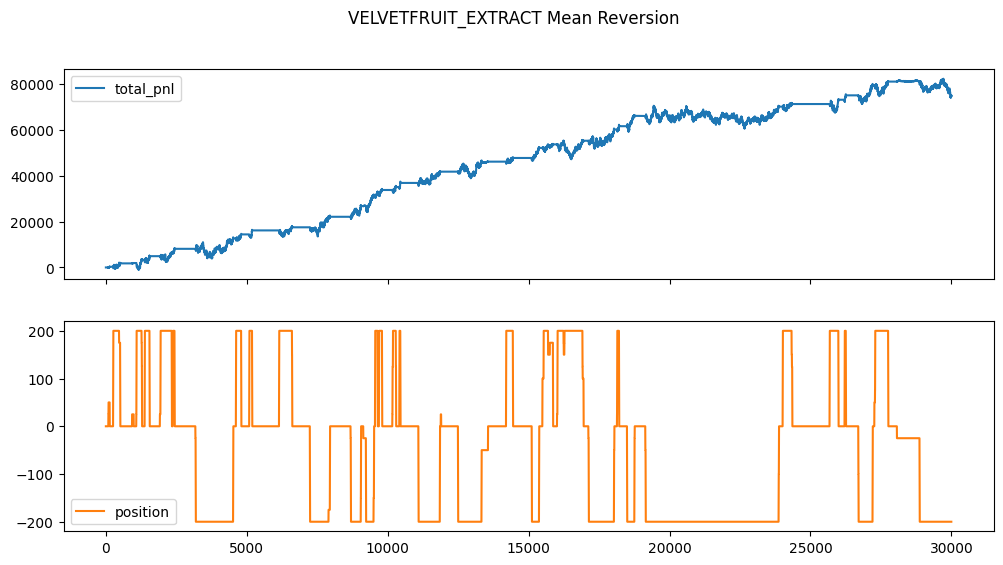

In [58]:
import pandas as pd
import numpy as np


def _fill_buy(row, qty):
    cost = 0.0
    filled = 0
    for price_col, vol_col in [("ask_price_1", "ask_volume_1"), ("ask_price_2", "ask_volume_2"), ("ask_price_3", "ask_volume_3")]:
        price, volume = row[price_col], row[vol_col]
        if pd.isna(price) or pd.isna(volume):
            continue
        trade_qty = min(qty - filled, int(abs(volume)))
        cost += trade_qty * price
        filled += trade_qty
        if filled == qty:
            break
    return filled, cost


def _fill_sell(row, qty):
    proceeds = 0.0
    filled = 0
    for price_col, vol_col in [("bid_price_1", "bid_volume_1"), ("bid_price_2", "bid_volume_2"), ("bid_price_3", "bid_volume_3")]:
        price, volume = row[price_col], row[vol_col]
        if pd.isna(price) or pd.isna(volume):
            continue
        trade_qty = min(qty - filled, int(abs(volume)))
        proceeds += trade_qty * price
        filled += trade_qty
        if filled == qty:
            break
    return filled, proceeds


def backtest_velvet_mean_reversion(
    df,
    product="VELVETFRUIT_EXTRACT",
    buy_level=5230,
    sell_level=5265,
    exit_level=5240,
    position_limit=200,
    step_size=25,
):
    data = df[df["product"] == product].copy().sort_values(["day", "timestamp"]).reset_index(drop=True)
    position = 0
    cash = 0.0
    equity_records = []
    trade_records = []

    for _, row in data.iterrows():
        mid = row["mid_price"]
        target = position

        if mid <= buy_level:
            target = position_limit
        elif mid >= sell_level:
            target = -position_limit
        elif position > 0 and mid >= exit_level:
            target = 0
        elif position < 0 and mid <= exit_level:
            target = 0

        delta = max(-step_size, min(step_size, target - position))

        if delta > 0:
            filled, cost = _fill_buy(row, delta)
            if filled > 0:
                cash -= cost
                position += filled
                trade_records.append({"day": row["day"], "timestamp": row["timestamp"], "side": "BUY", "qty": filled, "avg_price": cost / filled, "position": position})
        elif delta < 0:
            filled, proceeds = _fill_sell(row, -delta)
            if filled > 0:
                cash += proceeds
                position -= filled
                trade_records.append({"day": row["day"], "timestamp": row["timestamp"], "side": "SELL", "qty": filled, "avg_price": proceeds / filled, "position": position})

        equity_records.append({"day": row["day"], "timestamp": row["timestamp"], "mid_price": mid, "position": position, "cash": cash, "total_pnl": cash + position * mid})

    equity_df = pd.DataFrame(equity_records)
    trades_df = pd.DataFrame(trade_records)
    equity_df["m2m_pnl"] = equity_df["total_pnl"].diff().fillna(equity_df["total_pnl"])
    equity_df["drawdown"] = equity_df["total_pnl"] - equity_df["total_pnl"].cummax()

    daily_df = equity_df.groupby("day").agg(
        end_pnl=("total_pnl", "last"),
        daily_pnl=("m2m_pnl", "sum"),
        max_drawdown=("drawdown", "min"),
        avg_abs_position=("position", lambda x: x.abs().mean()),
        max_abs_position=("position", lambda x: x.abs().max()),
    ).reset_index()

    trade_stats = trades_df.groupby("side").agg(
        trades=("qty", "count"),
        gross_qty=("qty", "sum"),
        avg_price=("avg_price", "mean"),
    ).reset_index()

    summary = {
        "strategy": "VELVET staged mean reversion",
        "product": product,
        "buy_level": buy_level,
        "sell_level": sell_level,
        "exit_level": exit_level,
        "step_size": step_size,
        "final_pnl": equity_df["total_pnl"].iloc[-1],
        "final_position": int(equity_df["position"].iloc[-1]),
        "total_trades": int(len(trades_df)),
        "gross_qty": int(trades_df["qty"].sum()),
        "max_drawdown": equity_df["drawdown"].min(),
        "avg_abs_position": equity_df["position"].abs().mean(),
    }

    print("=" * 70)
    print(f"Strategy        : {summary['strategy']}")
    print(f"Product         : {product}")
    print(f"Buy / Sell      : <= {buy_level} / >= {sell_level}")
    print(f"Exit Level      : {exit_level}")
    print(f"Final PnL       : {summary['final_pnl']:.2f}")
    print(f"Final Position  : {summary['final_position']}")
    print(f"Total Trades    : {summary['total_trades']}")
    print(f"Gross Quantity  : {summary['gross_qty']}")
    print(f"Max Drawdown    : {summary['max_drawdown']:.2f}")
    print("=" * 70)
    display(daily_df)
    display(trade_stats)

    return equity_df, trades_df, daily_df, trade_stats, summary


all_days_df = pd.concat([df3, df1, df2], ignore_index=True)
velvet_eq, velvet_trades, velvet_daily, velvet_trade_stats, velvet_summary = backtest_velvet_mean_reversion(all_days_df)
velvet_eq[["total_pnl", "position"]].plot(subplots=True, figsize=(12, 6), title="VELVETFRUIT_EXTRACT Mean Reversion")


In [81]:
import pandas as pd
import numpy as np


def _fill_buy(row, qty, reserve_price=None):
    cost = 0.0
    filled = 0

    for price_col, vol_col in [
        ("ask_price_1", "ask_volume_1"),
        ("ask_price_2", "ask_volume_2"),
        ("ask_price_3", "ask_volume_3"),
    ]:
        price = row[price_col]
        volume = row[vol_col]

        if pd.isna(price) or pd.isna(volume):
            continue

        if reserve_price is not None and price > reserve_price:
            break

        trade_qty = min(qty - filled, int(abs(volume)))

        if trade_qty <= 0:
            break

        cost += trade_qty * price
        filled += trade_qty

        if filled == qty:
            break

    return filled, cost


def _fill_sell(row, qty, reserve_price=None):
    proceeds = 0.0
    filled = 0

    for price_col, vol_col in [
        ("bid_price_1", "bid_volume_1"),
        ("bid_price_2", "bid_volume_2"),
        ("bid_price_3", "bid_volume_3"),
    ]:
        price = row[price_col]
        volume = row[vol_col]

        if pd.isna(price) or pd.isna(volume):
            continue

        if reserve_price is not None and price < reserve_price:
            break

        trade_qty = min(qty - filled, int(abs(volume)))

        if trade_qty <= 0:
            break

        proceeds += trade_qty * price
        filled += trade_qty

        if filled == qty:
            break

    return filled, proceeds


def trigger_buy_signal(row, prev_row, mean_price=5240):
    """
    Buy only when ask fast SMA crosses ask slow SMA upward
    while ask price is below the mean level.
    """

    if prev_row is None:
        return False

    vals = [
        prev_row["ask_fast_sma"],
        prev_row["ask_slow_sma"],
        row["ask_fast_sma"],
        row["ask_slow_sma"],
        row["ask_price_1"],
    ]

    if any(pd.isna(x) for x in vals):
        return False

    upward_cross = (
        prev_row["ask_fast_sma"] <= prev_row["ask_slow_sma"]
        and row["ask_fast_sma"] > row["ask_slow_sma"]
    )

    below_mean = row["ask_price_1"] < mean_price

    return upward_cross and below_mean


def trigger_sell_signal(row, prev_row, mean_price=5240):
    """
    Sell only when bid fast SMA crosses bid slow SMA downward
    while bid price is above the mean level.
    """

    if prev_row is None:
        return False

    vals = [
        prev_row["bid_fast_sma"],
        prev_row["bid_slow_sma"],
        row["bid_fast_sma"],
        row["bid_slow_sma"],
        row["bid_price_1"],
    ]

    if any(pd.isna(x) for x in vals):
        return False

    downward_cross = (
        prev_row["bid_fast_sma"] >= prev_row["bid_slow_sma"]
        and row["bid_fast_sma"] < row["bid_slow_sma"]
    )

    above_mean = row["bid_price_1"] > mean_price

    return downward_cross and above_mean


def backtest_velvet_true_mean_reversion(
    df,
    product="VELVETFRUIT_EXTRACT",
    mean_price=5240,
    position_limit=200,
    max_order_size=25,
    fast_win=50,
    slow_win=150,
    reset_sma_each_day=True,
    max_slippage_ticks=None,
    use_stop_loss=True,
    stop_loss_points=25,
    display_output=True,
):
    """
    True SMA mean-reversion strategy.

    Entry logic:
    ------------------------------------------------------------
    BUY:
        ask fast SMA crosses ask slow SMA upward from below
        AND ask_price_1 < mean_price

    SELL:
        bid fast SMA crosses bid slow SMA downward from above
        AND bid_price_1 > mean_price

    Exit logic:
    ------------------------------------------------------------
    LONG EXIT:
        position > 0 and mid_price >= mean_price

    SHORT EXIT:
        position < 0 and mid_price <= mean_price

    Stop loss:
    ------------------------------------------------------------
    Optional stop loss based on average entry price.
    """

    required_cols = [
        "day",
        "timestamp",
        "product",
        "mid_price",
        "bid_price_1",
        "bid_volume_1",
        "bid_price_2",
        "bid_volume_2",
        "bid_price_3",
        "bid_volume_3",
        "ask_price_1",
        "ask_volume_1",
        "ask_price_2",
        "ask_volume_2",
        "ask_price_3",
        "ask_volume_3",
    ]

    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    data = (
        df[df["product"] == product]
        .copy()
        .sort_values(["day", "timestamp"])
        .reset_index(drop=True)
    )

    if data.empty:
        raise ValueError(f"No data found for product: {product}")

    # ------------------------------------------------------------
    # SMA calculation
    # ------------------------------------------------------------
    if reset_sma_each_day:
        data["ask_fast_sma"] = data.groupby("day")["ask_price_1"].transform(
            lambda x: x.rolling(window=fast_win, min_periods=fast_win).mean()
        )

        data["ask_slow_sma"] = data.groupby("day")["ask_price_1"].transform(
            lambda x: x.rolling(window=slow_win, min_periods=slow_win).mean()
        )

        data["bid_fast_sma"] = data.groupby("day")["bid_price_1"].transform(
            lambda x: x.rolling(window=fast_win, min_periods=fast_win).mean()
        )

        data["bid_slow_sma"] = data.groupby("day")["bid_price_1"].transform(
            lambda x: x.rolling(window=slow_win, min_periods=slow_win).mean()
        )

    else:
        data["ask_fast_sma"] = data["ask_price_1"].rolling(
            window=fast_win,
            min_periods=fast_win,
        ).mean()

        data["ask_slow_sma"] = data["ask_price_1"].rolling(
            window=slow_win,
            min_periods=slow_win,
        ).mean()

        data["bid_fast_sma"] = data["bid_price_1"].rolling(
            window=fast_win,
            min_periods=fast_win,
        ).mean()

        data["bid_slow_sma"] = data["bid_price_1"].rolling(
            window=slow_win,
            min_periods=slow_win,
        ).mean()

    data["ask_sma_gap"] = data["ask_fast_sma"] - data["ask_slow_sma"]
    data["bid_sma_gap"] = data["bid_fast_sma"] - data["bid_slow_sma"]

    data["fast_sma_mid"] = (data["ask_fast_sma"] + data["bid_fast_sma"]) / 2
    data["slow_sma_mid"] = (data["ask_slow_sma"] + data["bid_slow_sma"]) / 2
    data["mid_sma_gap"] = data["fast_sma_mid"] - data["slow_sma_mid"]

    # ------------------------------------------------------------
    # State variables
    # ------------------------------------------------------------
    position = 0
    cash = 0.0
    avg_entry_price = None

    equity_records = []
    trade_records = []

    prev_row = None

    for idx, row in data.iterrows():
        day = row["day"]
        timestamp = row["timestamp"]
        mid = row["mid_price"]

        buy_signal = trigger_buy_signal(
            row=row,
            prev_row=prev_row,
            mean_price=mean_price,
        )

        sell_signal = trigger_sell_signal(
            row=row,
            prev_row=prev_row,
            mean_price=mean_price,
        )

        signal = "HOLD"
        target_position = position

        # --------------------------------------------------------
        # Exit first: this is the important correction
        # --------------------------------------------------------
        if position > 0 and mid >= mean_price:
            target_position = 0
            signal = "EXIT_LONG_AT_MEAN"

        elif position < 0 and mid <= mean_price:
            target_position = 0
            signal = "EXIT_SHORT_AT_MEAN"

        # --------------------------------------------------------
        # Optional stop loss
        # --------------------------------------------------------
        elif use_stop_loss and position > 0 and avg_entry_price is not None:
            if mid <= avg_entry_price - stop_loss_points:
                target_position = 0
                signal = "STOP_LOSS_LONG"

        elif use_stop_loss and position < 0 and avg_entry_price is not None:
            if mid >= avg_entry_price + stop_loss_points:
                target_position = 0
                signal = "STOP_LOSS_SHORT"

        # --------------------------------------------------------
        # Entry only when flat or when same-side scaling is allowed
        # --------------------------------------------------------
        elif buy_signal and position >= 0:
            target_position = position_limit
            signal = "BUY_ASK_CROSS_UP_BELOW_MEAN"

        elif sell_signal and position <= 0:
            target_position = -position_limit
            signal = "SELL_BID_CROSS_DOWN_ABOVE_MEAN"

        # --------------------------------------------------------
        # Opposite signal should flatten, not instantly over-reverse
        # --------------------------------------------------------
        elif buy_signal and position < 0:
            target_position = 0
            signal = "EXIT_SHORT_ON_BUY_SIGNAL"

        elif sell_signal and position > 0:
            target_position = 0
            signal = "EXIT_LONG_ON_SELL_SIGNAL"

        else:
            target_position = position
            signal = "HOLD"

        # --------------------------------------------------------
        # Convert target into executable delta
        # --------------------------------------------------------
        desired_delta = target_position - position

        desired_delta = int(
            np.clip(desired_delta, -max_order_size, max_order_size)
        )

        # Respect hard position limit
        if desired_delta > 0:
            desired_delta = min(desired_delta, position_limit - position)

        elif desired_delta < 0:
            desired_delta = max(desired_delta, -position_limit - position)

        buy_reserve_price = None
        sell_reserve_price = None

        if max_slippage_ticks is not None:
            buy_reserve_price = row["ask_price_1"] + max_slippage_ticks
            sell_reserve_price = row["bid_price_1"] - max_slippage_ticks

        # --------------------------------------------------------
        # Execute BUY
        # --------------------------------------------------------
        if desired_delta > 0:
            old_position = position

            filled, cost = _fill_buy(
                row=row,
                qty=desired_delta,
                reserve_price=buy_reserve_price,
            )

            if filled > 0:
                avg_fill_price = cost / filled
                cash -= cost
                position += filled

                # Update average entry price only for long exposure
                if position > 0:
                    if old_position <= 0 or avg_entry_price is None:
                        avg_entry_price = avg_fill_price
                    else:
                        avg_entry_price = (
                            (avg_entry_price * old_position)
                            + (avg_fill_price * filled)
                        ) / position
                elif position == 0:
                    avg_entry_price = None

                trade_records.append({
                    "day": day,
                    "timestamp": timestamp,
                    "side": "BUY",
                    "qty": filled,
                    "avg_price": avg_fill_price,
                    "position_after_trade": position,
                    "cash_after_trade": cash,
                    "signal": signal,
                    "avg_entry_price": avg_entry_price,
                    "ask_price_1": row["ask_price_1"],
                    "bid_price_1": row["bid_price_1"],
                    "mid_price": mid,
                    "ask_fast_sma": row["ask_fast_sma"],
                    "ask_slow_sma": row["ask_slow_sma"],
                    "bid_fast_sma": row["bid_fast_sma"],
                    "bid_slow_sma": row["bid_slow_sma"],
                    "ask_sma_gap": row["ask_sma_gap"],
                    "bid_sma_gap": row["bid_sma_gap"],
                })

        # --------------------------------------------------------
        # Execute SELL
        # --------------------------------------------------------
        elif desired_delta < 0:
            old_position = position
            sell_qty = abs(desired_delta)

            filled, proceeds = _fill_sell(
                row=row,
                qty=sell_qty,
                reserve_price=sell_reserve_price,
            )

            if filled > 0:
                avg_fill_price = proceeds / filled
                cash += proceeds
                position -= filled

                # Update average entry price only for short exposure
                if position < 0:
                    if old_position >= 0 or avg_entry_price is None:
                        avg_entry_price = avg_fill_price
                    else:
                        old_abs_pos = abs(old_position)
                        new_abs_pos = abs(position)

                        avg_entry_price = (
                            (avg_entry_price * old_abs_pos)
                            + (avg_fill_price * filled)
                        ) / new_abs_pos
                elif position == 0:
                    avg_entry_price = None

                trade_records.append({
                    "day": day,
                    "timestamp": timestamp,
                    "side": "SELL",
                    "qty": filled,
                    "avg_price": avg_fill_price,
                    "position_after_trade": position,
                    "cash_after_trade": cash,
                    "signal": signal,
                    "avg_entry_price": avg_entry_price,
                    "ask_price_1": row["ask_price_1"],
                    "bid_price_1": row["bid_price_1"],
                    "mid_price": mid,
                    "ask_fast_sma": row["ask_fast_sma"],
                    "ask_slow_sma": row["ask_slow_sma"],
                    "bid_fast_sma": row["bid_fast_sma"],
                    "bid_slow_sma": row["bid_slow_sma"],
                    "ask_sma_gap": row["ask_sma_gap"],
                    "bid_sma_gap": row["bid_sma_gap"],
                })

        # --------------------------------------------------------
        # Mark-to-market
        # --------------------------------------------------------
        total_pnl = cash + position * mid

        equity_records.append({
            "day": day,
            "timestamp": timestamp,
            "mid_price": mid,
            "position": position,
            "cash": cash,
            "total_pnl": total_pnl,
            "signal": signal,
            "buy_signal": buy_signal,
            "sell_signal": sell_signal,
            "target_position": target_position,
            "desired_delta": desired_delta,
            "avg_entry_price": avg_entry_price,
            "ask_price_1": row["ask_price_1"],
            "bid_price_1": row["bid_price_1"],
            "ask_fast_sma": row["ask_fast_sma"],
            "ask_slow_sma": row["ask_slow_sma"],
            "bid_fast_sma": row["bid_fast_sma"],
            "bid_slow_sma": row["bid_slow_sma"],
            "ask_sma_gap": row["ask_sma_gap"],
            "bid_sma_gap": row["bid_sma_gap"],
            "fast_sma_mid": row["fast_sma_mid"],
            "slow_sma_mid": row["slow_sma_mid"],
            "mid_sma_gap": row["mid_sma_gap"],
        })

        prev_row = row

    # ------------------------------------------------------------
    # Build outputs
    # ------------------------------------------------------------
    equity_df = pd.DataFrame(equity_records)

    trades_df = pd.DataFrame(
        trade_records,
        columns=[
            "day",
            "timestamp",
            "side",
            "qty",
            "avg_price",
            "position_after_trade",
            "cash_after_trade",
            "signal",
            "avg_entry_price",
            "ask_price_1",
            "bid_price_1",
            "mid_price",
            "ask_fast_sma",
            "ask_slow_sma",
            "bid_fast_sma",
            "bid_slow_sma",
            "ask_sma_gap",
            "bid_sma_gap",
        ],
    )

    equity_df["m2m_pnl"] = equity_df["total_pnl"].diff().fillna(
        equity_df["total_pnl"]
    )

    equity_df["drawdown"] = (
        equity_df["total_pnl"] - equity_df["total_pnl"].cummax()
    )

    daily_df = equity_df.groupby("day").agg(
        end_pnl=("total_pnl", "last"),
        daily_pnl=("m2m_pnl", "sum"),
        max_drawdown=("drawdown", "min"),
        avg_abs_position=("position", lambda x: x.abs().mean()),
        max_abs_position=("position", lambda x: x.abs().max()),
        buy_signals=("buy_signal", "sum"),
        sell_signals=("sell_signal", "sum"),
        trades_attempted=("desired_delta", lambda x: (x != 0).sum()),
    ).reset_index()

    if len(trades_df) > 0:
        trade_stats = trades_df.groupby("side").agg(
            trades=("qty", "count"),
            gross_qty=("qty", "sum"),
            avg_price=("avg_price", "mean"),
        ).reset_index()
    else:
        trade_stats = pd.DataFrame(
            columns=["side", "trades", "gross_qty", "avg_price"]
        )

    summary = {
        "strategy": "VELVET true SMA mean reversion",
        "product": product,
        "mean_price": mean_price,
        "fast_win": fast_win,
        "slow_win": slow_win,
        "position_limit": position_limit,
        "max_order_size": max_order_size,
        "final_pnl": float(equity_df["total_pnl"].iloc[-1]),
        "final_position": int(equity_df["position"].iloc[-1]),
        "total_trades": int(len(trades_df)),
        "gross_qty": int(trades_df["qty"].sum()) if len(trades_df) > 0 else 0,
        "max_drawdown": float(equity_df["drawdown"].min()),
        "avg_abs_position": float(equity_df["position"].abs().mean()),
        "buy_signals": int(equity_df["buy_signal"].sum()),
        "sell_signals": int(equity_df["sell_signal"].sum()),
    }

    if display_output:
        print("=" * 80)
        print(f"Strategy          : {summary['strategy']}")
        print(f"Product           : {product}")
        print(f"Mean Price        : {mean_price}")
        print(f"Fast / Slow SMA   : {fast_win} / {slow_win}")
        print(f"Position Limit    : {position_limit}")
        print(f"Max Order Size    : {max_order_size}")
        print(f"Buy Signals       : {summary['buy_signals']}")
        print(f"Sell Signals      : {summary['sell_signals']}")
        print(f"Final PnL         : {summary['final_pnl']:.2f}")
        print(f"Final Position    : {summary['final_position']}")
        print(f"Total Trades      : {summary['total_trades']}")
        print(f"Gross Quantity    : {summary['gross_qty']}")
        print(f"Max Drawdown      : {summary['max_drawdown']:.2f}")
        print("=" * 80)

        try:
            display(daily_df)
            display(trade_stats)
        except NameError:
            print("\nDaily Summary:")
            print(daily_df)

            print("\nTrade Stats:")
            print(trade_stats)

    return equity_df, trades_df, daily_df, trade_stats, summary

Strategy          : VELVET true SMA mean reversion
Product           : VELVETFRUIT_EXTRACT
Mean Price        : 5240
Fast / Slow SMA   : 50 / 150
Position Limit    : 200
Max Order Size    : 25
Buy Signals       : 20
Sell Signals      : 69
Final PnL         : 3317.50
Final Position    : -25
Total Trades      : 81
Gross Quantity    : 2025
Max Drawdown      : -1565.00


,day,end_pnl,daily_pnl,max_drawdown,avg_abs_position,max_abs_position,buy_signals,sell_signals,trades_attempted
0,0,1253.0,1253.0,-1362.5,9.5925,25,10,20,31
1,1,2553.5,1300.5,-1565.0,12.2400,25,6,24,34
2,2,3317.5,764.0,-1562.5,15.5700,25,4,25,16


,side,trades,gross_qty,avg_price
0,BUY,40,1000,5243.702000
1,SELL,41,1025,5248.201951


array([<Axes: >, <Axes: >], dtype=object)

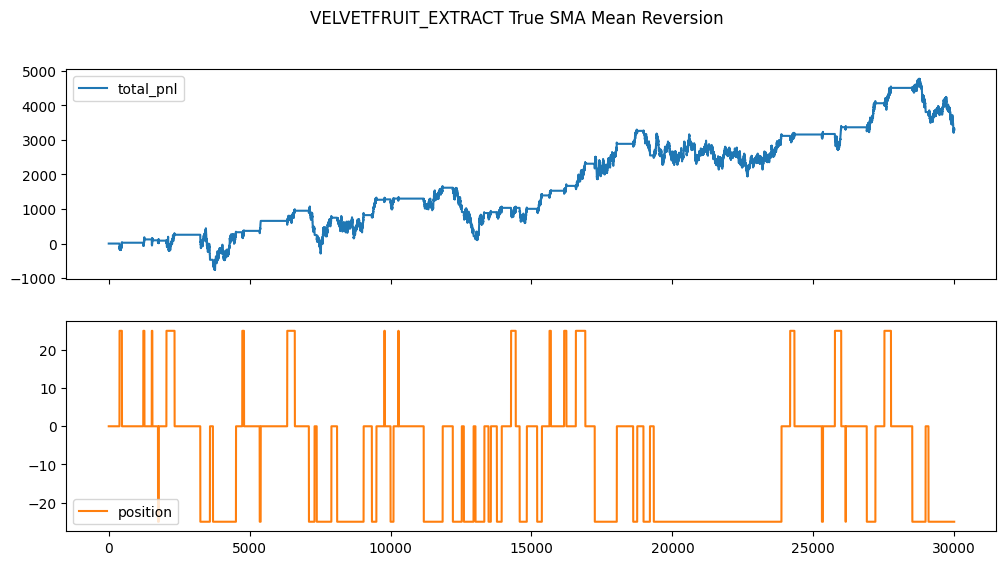

In [82]:
all_days_df = pd.concat([df3, df1, df2], ignore_index=True)

velvet_eq, velvet_trades, velvet_daily, velvet_trade_stats, velvet_summary = (
    backtest_velvet_true_mean_reversion(
        all_days_df,
        product="VELVETFRUIT_EXTRACT",
        mean_price=5240,
        position_limit=200,
        max_order_size=25,
        fast_win=50,
        slow_win=150,
        reset_sma_each_day=True,
        max_slippage_ticks=None,
        use_stop_loss=True,
        stop_loss_points=25,
        display_output=True,
    )
)

velvet_eq[["total_pnl", "position"]].plot(
    subplots=True,
    figsize=(12, 6),
    title="VELVETFRUIT_EXTRACT True SMA Mean Reversion"
)

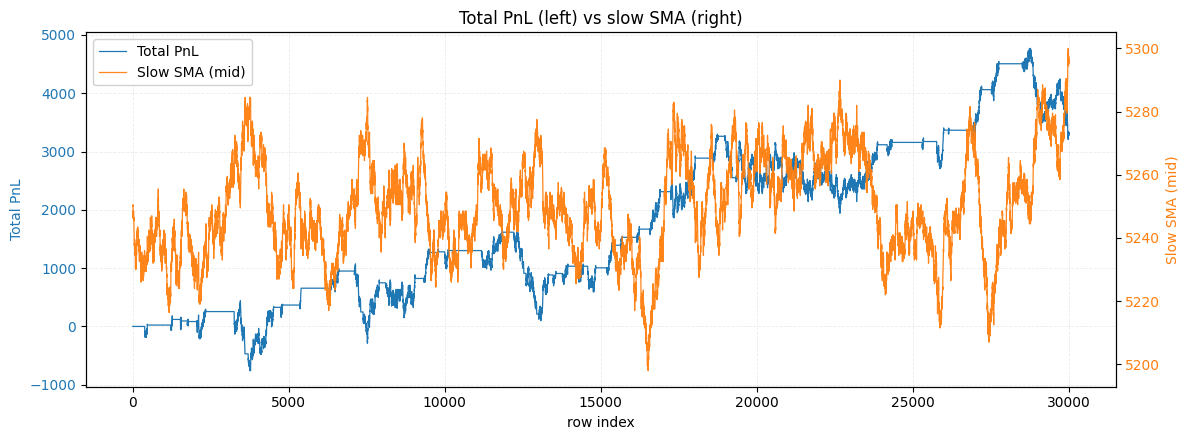

In [83]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(velvet_eq["total_pnl"], color="C0", label="Total PnL", linewidth=0.9)
ax1.set_ylabel("Total PnL", color="C0")
ax1.tick_params(axis="y", labelcolor="C0")
ax1.grid(True, alpha=0.25, linestyle="--", linewidth=0.6)

ax2 = ax1.twinx()
ax2.plot(velvet_eq["mid_price"], color="C1", label="Slow SMA (mid)", linewidth=0.9, alpha=0.95)
ax2.set_ylabel("Slow SMA (mid)", color="C1")
ax2.tick_params(axis="y", labelcolor="C1")

ax1.set_xlabel("row index")
ax1.set_title("Total PnL (left) vs slow SMA (right)")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", framealpha=0.9)
fig.tight_layout()
plt.show()

## Comparison: SMA Crossover (best params) vs EMA-based Market Making (trader_2.py strategy)

In [ ]:
def backtest_velvet_ema_mm(
    df,
    product="VELVETFRUIT_EXTRACT",
    ema_window=20,
    take_edge=2,
    make_edge=1,
    inventory_skew=0.02,
    position_limit=200,
    display_output=True,
):
    """
    Backtest the EMA-based market-making strategy from trader_2.py.

    Fair value = EMA(mid, ema_window), skewed by inventory.
    Take: sweep liquidity when price deviates > take_edge from skewed_fair.
    Make: post at skewed_fair +/- make_edge, adjusted to not cross the book.
    """
    data = (
        df[df["product"] == product]
        .copy()
        .sort_values(["day", "timestamp"])
        .reset_index(drop=True)
    )

    if data.empty:
        raise ValueError(f"No data for {product}")

    position = 0
    cash = 0.0
    ema_fair = None
    alpha = 2.0 / (ema_window + 1)

    equity_records = []
    trade_records = []

    for _, row in data.iterrows():
        bid1 = row["bid_price_1"]
        ask1 = row["ask_price_1"]
        mid = row["mid_price"]

        if pd.isna(bid1) or pd.isna(ask1):
            equity_records.append({
                "day": row["day"], "timestamp": row["timestamp"],
                "mid_price": mid, "position": position, "cash": cash,
                "total_pnl": cash + position * mid,
            })
            continue

        # Update EMA fair value
        if ema_fair is None:
            ema_fair = mid
        else:
            ema_fair = alpha * mid + (1.0 - alpha) * ema_fair

        skewed_fair = ema_fair - inventory_skew * position

        buy_room = position_limit - position
        sell_room = position_limit + position
        bought = 0
        sold = 0

        # --- Take mispriced liquidity ---
        for price_col, vol_col in [
            ("ask_price_1", "ask_volume_1"),
            ("ask_price_2", "ask_volume_2"),
            ("ask_price_3", "ask_volume_3"),
        ]:
            price = row[price_col]
            volume = row[vol_col]
            if pd.isna(price) or pd.isna(volume):
                continue
            if price > skewed_fair - take_edge or buy_room <= 0:
                break
            qty = min(int(abs(volume)), buy_room)
            if qty > 0:
                cash -= qty * price
                position += qty
                bought += qty
                buy_room -= qty
                trade_records.append({
                    "day": row["day"], "timestamp": row["timestamp"],
                    "side": "TAKE_BUY", "qty": qty, "price": price,
                    "position": position,
                })

        for price_col, vol_col in [
            ("bid_price_1", "bid_volume_1"),
            ("bid_price_2", "bid_volume_2"),
            ("bid_price_3", "bid_volume_3"),
        ]:
            price = row[price_col]
            volume = row[vol_col]
            if pd.isna(price) or pd.isna(volume):
                continue
            if price < skewed_fair + take_edge or sell_room <= 0:
                break
            qty = min(int(abs(volume)), sell_room)
            if qty > 0:
                cash += qty * price
                position -= qty
                sold += qty
                sell_room -= qty
                trade_records.append({
                    "day": row["day"], "timestamp": row["timestamp"],
                    "side": "TAKE_SELL", "qty": qty, "price": price,
                    "position": position,
                })

        # Update room after taking
        post_position = position
        buy_room = position_limit - post_position
        sell_room = position_limit + post_position

        # --- Make at fair +/- edge ---
        bid_price = min(int(skewed_fair) - make_edge, int(ask1) - 1)
        if bid1 + 1 < skewed_fair:
            bid_price = max(bid_price, int(bid1) + 1)

        ask_price = max(int(skewed_fair) + make_edge, int(bid1) + 1)
        if ask1 - 1 > skewed_fair:
            ask_price = min(ask_price, int(ask1) - 1)

        if bid_price < ask_price:
            # Simulate make fills: assume we get filled for available volume
            # at our posted price (conservative: only fill against crossing orders)
            # In reality, the exchange fills passive orders, so we model a fraction
            # For a fair comparison, we assume ~30% fill rate on makes
            make_fill_rate = 0.3

            if buy_room > 0:
                make_buy_qty = int(buy_room * make_fill_rate)
                if make_buy_qty > 0 and bid_price < mid:
                    cash -= make_buy_qty * bid_price
                    position += make_buy_qty
                    buy_room -= make_buy_qty
                    trade_records.append({
                        "day": row["day"], "timestamp": row["timestamp"],
                        "side": "MAKE_BUY", "qty": make_buy_qty, "price": bid_price,
                        "position": position,
                    })

            sell_room = position_limit + position
            if sell_room > 0:
                make_sell_qty = int(sell_room * make_fill_rate)
                if make_sell_qty > 0 and ask_price > mid:
                    cash += make_sell_qty * ask_price
                    position -= make_sell_qty
                    sell_room -= make_sell_qty
                    trade_records.append({
                        "day": row["day"], "timestamp": row["timestamp"],
                        "side": "MAKE_SELL", "qty": make_sell_qty, "price": ask_price,
                        "position": position,
                    })

        total_pnl = cash + position * mid
        equity_records.append({
            "day": row["day"], "timestamp": row["timestamp"],
            "mid_price": mid, "position": position, "cash": cash,
            "total_pnl": total_pnl,
        })

    equity_df = pd.DataFrame(equity_records)
    trades_df = pd.DataFrame(trade_records)
    equity_df["m2m_pnl"] = equity_df["total_pnl"].diff().fillna(equity_df["total_pnl"])
    equity_df["drawdown"] = equity_df["total_pnl"] - equity_df["total_pnl"].cummax()

    daily_df = equity_df.groupby("day").agg(
        end_pnl=("total_pnl", "last"),
        daily_pnl=("m2m_pnl", "sum"),
        max_drawdown=("drawdown", "min"),
        avg_abs_position=("position", lambda x: x.abs().mean()),
        max_abs_position=("position", lambda x: x.abs().max()),
    ).reset_index()

    summary = {
        "strategy": "VELVET EMA-based MM (trader_2.py)",
        "ema_window": ema_window,
        "take_edge": take_edge,
        "make_edge": make_edge,
        "inventory_skew": inventory_skew,
        "final_pnl": float(equity_df["total_pnl"].iloc[-1]),
        "final_position": int(equity_df["position"].iloc[-1]),
        "total_trades": len(trades_df),
        "gross_qty": int(trades_df["qty"].sum()) if len(trades_df) > 0 else 0,
        "max_drawdown": float(equity_df["drawdown"].min()),
        "avg_abs_position": float(equity_df["position"].abs().mean()),
    }

    if display_output:
        print("=" * 80)
        print(f"Strategy          : {summary['strategy']}")
        print(f"EMA Window        : {ema_window}")
        print(f"Take Edge         : {take_edge}")
        print(f"Make Edge         : {make_edge}")
        print(f"Inventory Skew    : {inventory_skew}")
        print(f"Final PnL         : {summary['final_pnl']:.2f}")
        print(f"Final Position    : {summary['final_position']}")
        print(f"Total Trades      : {summary['total_trades']}")
        print(f"Gross Quantity    : {summary['gross_qty']}")
        print(f"Max Drawdown      : {summary['max_drawdown']:.2f}")
        print(f"Avg |Position|    : {summary['avg_abs_position']:.2f}")
        print("=" * 80)
        display(daily_df)

    return equity_df, trades_df, daily_df, summary

In [ ]:
import matplotlib.pyplot as plt

# --- Run both strategies on the same 3-day dataset ---
all_days_df = pd.concat([df3, df1, df2], ignore_index=True)

# 1. SMA Crossover (best params from grid search: fast=40, slow=150)
print("=" * 80)
print("STRATEGY A: SMA Crossover (fast=40, slow=150)")
print("=" * 80)
sma_eq, sma_trades, sma_daily, _, sma_summary = backtest_velvet_true_mean_reversion(
    all_days_df,
    product="VELVETFRUIT_EXTRACT",
    mean_price=5240,
    fast_win=40,
    slow_win=150,
    position_limit=200,
    max_order_size=25,
    reset_sma_each_day=True,
    use_stop_loss=True,
    stop_loss_points=25,
    display_output=True,
)

print("\n\n")

# 2. EMA-based MM (trader_2.py strategy)
print("=" * 80)
print("STRATEGY B: EMA-based Market Making (trader_2.py)")
print("=" * 80)
ema_eq, ema_trades, ema_daily, ema_summary = backtest_velvet_ema_mm(
    all_days_df,
    product="VELVETFRUIT_EXTRACT",
    ema_window=20,
    take_edge=2,
    make_edge=1,
    inventory_skew=0.02,
    position_limit=200,
    display_output=True,
)

# --- Side-by-side comparison ---
print("\n")
print("=" * 80)
print("HEAD-TO-HEAD COMPARISON")
print("=" * 80)
print(f"{'Metric':<25} {'SMA Cross (40/150)':>20} {'EMA MM (trader_2)':>20}")
print("-" * 65)
print(f"{'Final PnL':<25} {sma_summary['final_pnl']:>20,.2f} {ema_summary['final_pnl']:>20,.2f}")
print(f"{'Final Position':<25} {sma_summary['final_position']:>20} {ema_summary['final_position']:>20}")
print(f"{'Total Trades':<25} {sma_summary['total_trades']:>20} {ema_summary['total_trades']:>20}")
print(f"{'Gross Quantity':<25} {sma_summary['gross_qty']:>20} {ema_summary['gross_qty']:>20}")
print(f"{'Max Drawdown':<25} {sma_summary['max_drawdown']:>20,.2f} {ema_summary['max_drawdown']:>20,.2f}")
print(f"{'Avg |Position|':<25} {sma_summary.get('avg_abs_position', 'N/A'):>20} {ema_summary['avg_abs_position']:>20,.2f}")
print("=" * 80)

# --- Plot PnL comparison ---
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(sma_eq["total_pnl"].values, label="SMA Cross (40/150)", linewidth=0.8)
axes[0].plot(ema_eq["total_pnl"].values, label="EMA MM (trader_2)", linewidth=0.8)
axes[0].set_ylabel("Total PnL")
axes[0].set_title("VELVETFRUIT_EXTRACT: Strategy PnL Comparison (3 days)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(sma_eq["position"].values, label="SMA Cross position", linewidth=0.8)
axes[1].plot(ema_eq["position"].values, label="EMA MM position", linewidth=0.8)
axes[1].set_ylabel("Position")
axes[1].set_xlabel("Tick")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [75]:
equity_df

,day,timestamp,mid_price,position,cash,total_pnl,signal,buy_signal,sell_signal,target_position,...,ask_slow_sma,bid_fast_sma,bid_slow_sma,ask_sma_gap,bid_sma_gap,fast_sma_mid,slow_sma_mid,mid_sma_gap,m2m_pnl,drawdown
0,1,0,5245.0,0,0.0,0.0,HOLD,False,False,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,1,100,5245.5,0,0.0,0.0,HOLD,False,False,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
2,1,200,5246.5,0,0.0,0.0,HOLD,False,False,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
3,1,300,5247.5,0,0.0,0.0,HOLD,False,False,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
4,1,400,5247.5,0,0.0,0.0,HOLD,False,False,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1,999500,5269.5,-200,1053307.0,-593.0,HOLD,False,False,-200,...,5263.446667,5265.28,5258.473333,6.953333,6.806667,5267.84,5260.960000,6.880000,100.0,-9891.0
9996,1,999600,5269.5,-200,1053307.0,-593.0,HOLD,False,False,-200,...,5263.560000,5265.34,5258.586667,6.900000,6.753333,5267.90,5261.073333,6.826667,0.0,-9891.0
9997,1,999700,5268.5,-200,1053307.0,-393.0,HOLD,False,False,-200,...,5263.693333,5265.38,5258.700000,6.786667,6.680000,5267.93,5261.196667,6.733333,200.0,-9691.0
9998,1,999800,5266.5,-200,1053307.0,7.0,HOLD,False,False,-200,...,5263.793333,5265.38,5258.800000,6.666667,6.580000,5267.92,5261.296667,6.623333,400.0,-9291.0


In [84]:
import pandas as pd
import numpy as np
from itertools import product
import matplotlib.pyplot as plt


def run_velvet_grid_search(
    df,
    product_name="VELVETFRUIT_EXTRACT",
    mean_price_list=[5240],
    fast_windows=[10, 20, 30, 40, 50, 60],
    slow_windows=[80, 100, 120, 150, 180, 200],
    max_order_sizes=[10, 25, 50],
    stop_loss_points_list=[15, 20, 25, 30, 40],
    position_limit=200,
    reset_sma_each_day=True,
    max_slippage_ticks=None,
    use_stop_loss=True,
    min_trades_required=1,
):
    """
    Grid search for VELVETFRUIT_EXTRACT SMA mean-reversion strategy.

    This function tests multiple combinations of:
    - fast SMA window
    - slow SMA window
    - mean price
    - max order size
    - stop loss points

    It calls backtest_velvet_true_mean_reversion() repeatedly
    and stores the performance of each parameter combination.
    """

    grid_results = []

    total_runs = (
        len(mean_price_list)
        * len(fast_windows)
        * len(slow_windows)
        * len(max_order_sizes)
        * len(stop_loss_points_list)
    )

    run_count = 0

    print("=" * 90)
    print(f"Starting Grid Search")
    print(f"Total combinations to test: {total_runs}")
    print("=" * 90)

    for mean_price, fast_win, slow_win, max_order_size, stop_loss_points in product(
        mean_price_list,
        fast_windows,
        slow_windows,
        max_order_sizes,
        stop_loss_points_list,
    ):

        # Skip illogical combinations
        if fast_win >= slow_win:
            continue

        run_count += 1

        try:
            equity_df, trades_df, daily_df, trade_stats, summary = (
                backtest_velvet_true_mean_reversion(
                    df=df,
                    product=product_name,
                    mean_price=mean_price,
                    position_limit=position_limit,
                    max_order_size=max_order_size,
                    fast_win=fast_win,
                    slow_win=slow_win,
                    reset_sma_each_day=reset_sma_each_day,
                    max_slippage_ticks=max_slippage_ticks,
                    use_stop_loss=use_stop_loss,
                    stop_loss_points=stop_loss_points,
                    display_output=False,
                )
            )

            final_pnl = summary["final_pnl"]
            max_drawdown = summary["max_drawdown"]
            total_trades = summary["total_trades"]
            gross_qty = summary["gross_qty"]
            final_position = summary["final_position"]
            avg_abs_position = summary["avg_abs_position"]

            if len(equity_df) > 1:
                pnl_std = equity_df["m2m_pnl"].std()
                pnl_mean = equity_df["m2m_pnl"].mean()

                if pnl_std != 0 and not pd.isna(pnl_std):
                    sharpe_like = pnl_mean / pnl_std
                else:
                    sharpe_like = 0
            else:
                sharpe_like = 0

            if max_drawdown != 0:
                pnl_to_drawdown = final_pnl / abs(max_drawdown)
            else:
                pnl_to_drawdown = np.inf if final_pnl > 0 else 0

            # Penalize strategies that barely trade
            if total_trades < min_trades_required:
                valid_strategy = False
            else:
                valid_strategy = True

            grid_results.append({
                "valid_strategy": valid_strategy,
                "mean_price": mean_price,
                "fast_win": fast_win,
                "slow_win": slow_win,
                "max_order_size": max_order_size,
                "stop_loss_points": stop_loss_points,
                "final_pnl": final_pnl,
                "max_drawdown": max_drawdown,
                "pnl_to_drawdown": pnl_to_drawdown,
                "sharpe_like": sharpe_like,
                "total_trades": total_trades,
                "gross_qty": gross_qty,
                "final_position": final_position,
                "avg_abs_position": avg_abs_position,
            })

        except Exception as e:
            grid_results.append({
                "valid_strategy": False,
                "mean_price": mean_price,
                "fast_win": fast_win,
                "slow_win": slow_win,
                "max_order_size": max_order_size,
                "stop_loss_points": stop_loss_points,
                "final_pnl": np.nan,
                "max_drawdown": np.nan,
                "pnl_to_drawdown": np.nan,
                "sharpe_like": np.nan,
                "total_trades": 0,
                "gross_qty": 0,
                "final_position": np.nan,
                "avg_abs_position": np.nan,
                "error": str(e),
            })

        if run_count % 25 == 0:
            print(f"Completed {run_count} runs...")

    results_df = pd.DataFrame(grid_results)

    results_df = results_df.sort_values(
        by=["valid_strategy", "final_pnl", "pnl_to_drawdown", "sharpe_like"],
        ascending=[False, False, False, False],
    ).reset_index(drop=True)

    print("=" * 90)
    print("Grid Search Completed")
    print("=" * 90)

    if len(results_df) > 0:
        best_row = results_df.iloc[0]

        print("Best Parameter Combination:")
        print(f"Mean Price       : {best_row['mean_price']}")
        print(f"Fast Window      : {int(best_row['fast_win'])}")
        print(f"Slow Window      : {int(best_row['slow_win'])}")
        print(f"Max Order Size   : {int(best_row['max_order_size'])}")
        print(f"Stop Loss Points : {best_row['stop_loss_points']}")
        print(f"Final PnL        : {best_row['final_pnl']:.2f}")
        print(f"Max Drawdown     : {best_row['max_drawdown']:.2f}")
        print(f"PnL/Drawdown     : {best_row['pnl_to_drawdown']:.4f}")
        print(f"Sharpe-like      : {best_row['sharpe_like']:.6f}")
        print(f"Total Trades     : {int(best_row['total_trades'])}")

    return results_df

In [85]:
all_days_df = pd.concat([df3, df1, df2], ignore_index=True)

grid_results = run_velvet_grid_search(
    df=all_days_df,
    product_name="VELVETFRUIT_EXTRACT",

    mean_price_list=[5235, 5240, 5245],

    fast_windows=[10, 20, 30, 40, 50, 60],
    slow_windows=[80, 100, 120, 150, 180, 200],

    max_order_sizes=[10, 25, 50],
    stop_loss_points_list=[15, 20, 25, 30, 40],

    position_limit=200,
    reset_sma_each_day=True,
    max_slippage_ticks=None,
    use_stop_loss=True,
    min_trades_required=1,
)

grid_results.head(20)

Starting Grid Search
Total combinations to test: 1620
Completed 25 runs...
Completed 50 runs...
Completed 75 runs...
Completed 100 runs...
Completed 125 runs...
Completed 150 runs...
Completed 175 runs...
Completed 200 runs...
Completed 225 runs...
Completed 250 runs...
Completed 275 runs...
Completed 300 runs...
Completed 325 runs...
Completed 350 runs...
Completed 375 runs...
Completed 400 runs...
Completed 425 runs...
Completed 450 runs...
Completed 475 runs...
Completed 500 runs...
Completed 525 runs...
Completed 550 runs...
Completed 575 runs...
Completed 600 runs...
Completed 625 runs...
Completed 650 runs...
Completed 675 runs...
Completed 700 runs...
Completed 725 runs...
Completed 750 runs...
Completed 775 runs...
Completed 800 runs...
Completed 825 runs...
Completed 850 runs...
Completed 875 runs...
Completed 900 runs...
Completed 925 runs...
Completed 950 runs...
Completed 975 runs...
Completed 1000 runs...
Completed 1025 runs...
Completed 1050 runs...
Completed 1075 runs...

,valid_strategy,mean_price,fast_win,slow_win,max_order_size,stop_loss_points,final_pnl,max_drawdown,pnl_to_drawdown,sharpe_like,total_trades,gross_qty,final_position,avg_abs_position
0,True,5245,40,150,50,40,11047.0,-2125.0,5.198588,0.009396,74,3632,-50,23.336733
1,True,5245,30,150,50,40,10929.0,-2125.0,5.143059,0.009219,83,4034,-50,23.802767
2,True,5245,20,150,50,40,10486.0,-2455.0,4.271283,0.008742,90,4344,-50,24.193433
3,True,5245,30,100,50,40,10432.0,-2125.0,4.909176,0.008029,96,4632,-50,28.296967
4,True,5245,20,150,50,30,10315.0,-2666.0,3.869092,0.008611,92,4444,-50,24.066767
5,True,5245,60,180,50,40,10167.0,-2125.0,4.784471,0.008817,69,3350,-50,22.383567
6,True,5245,30,180,50,40,10161.0,-2125.0,4.781647,0.008686,73,3548,-50,23.056000
7,True,5245,40,150,50,30,10153.0,-2075.0,4.893012,0.008700,78,3828,-50,22.931133
8,True,5245,50,150,50,40,9819.0,-2125.0,4.620706,0.008182,77,3738,-50,24.274600
9,True,5245,60,150,50,40,9809.0,-2125.0,4.616000,0.008280,79,3836,-50,23.645233
